# FinanceBench RAG — Notebook 03b: Answer Generation and Accuracy

Notebooks 01–03a measured **retrieval**: did we find the right page? This notebook measures what a user actually sees: **is the final answer correct?**

Four setups, same LLM, same questions:

| Setup | Context given to the LLM | Why it's here |
|---|---|---|
| `closed_book` | none | How often does the LLM hallucinate from memory? |
| `dense_rag` | top-5 chunks from dense search | the baseline RAG system |
| `rewrite_rag` | top-5 chunks from query rewriting | **the extension** |
| `oracle` | the gold evidence page(s) | upper bound: accuracy with *perfect* retrieval |

Grading mirrors the FinanceBench paper: each answer is **correct**, **incorrect** (a wrong answer = hallucination), or **refused** (the model says it can't answer).

**Runtime: CPU is fine** (no GPU needed). **This may take 2 days of free quota:** the notebook saves every response, so if it stops with "daily limit", just rerun it the next day and it continues where it left off.

## 0. Setup

In [3]:
!pip -q install groq

In [4]:
import os, re, time, json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from google.colab import drive
drive.mount('/content/drive')
ROOT = '/content/drive/MyDrive/financebench_rag'
REPO = 'https://raw.githubusercontent.com/patronus-ai/financebench/main'

qs = pd.read_json(f'{REPO}/data/financebench_open_source.jsonl', lines=True)
contexts = json.load(open(f'{ROOT}/contexts.json'))   # saved by Notebook 03a
print(len(qs), 'questions |', len(contexts), 'with retrieved contexts')

Mounted at /content/drive
150 questions | 150 with retrieved contexts


## LLM helper (Groq)

Every call goes through one function, `llm()`, which does three jobs:

1. **Caching.** Each response is appended to `llm_cache.jsonl` on your Drive. Asking the same thing again returns the saved answer instantly and costs nothing. So reruns are free, and an interrupted run **resumes where it stopped**.
2. **Pacing.** Groq's free tier allows about 8,000 tokens per minute and 30 requests per minute per model. The helper waits as needed to stay under that.
3. **Daily limit.** Each model also has a daily token cap (about 200K). If it's hit, the helper stops with a clear message. Progress is saved; just rerun the notebook later (the cap resets daily).

📘 **Concept: tokens and temperature.** You pay (in quota) for **input + output tokens**: the prompt, the retrieved context, and the reply. `temperature=0` makes the model pick its most likely wording every time, so results are as repeatable as possible.

📘 **Concept: reasoning models.** `gpt-oss` models "think" before answering, and that thinking also uses tokens. We set `reasoning_effort='low'` to keep it short.

In [5]:
import json, hashlib
from groq import Groq, RateLimitError, APIConnectionError, InternalServerError
from google.colab import userdata

try:
    client = Groq(api_key=userdata.get('GROQ_API_KEY'), max_retries=0)
except Exception as e:
    raise RuntimeError('Add your key in the 🔑 Secrets sidebar as GROQ_API_KEY and switch on notebook access.') from e

CACHE_PATH = f'{ROOT}/llm_cache.jsonl'
cache = {}
if os.path.exists(CACHE_PATH):
    with open(CACHE_PATH) as f:
        for line in f:
            rec = json.loads(line)
            cache[rec['key']] = rec
print(len(cache), 'cached LLM responses on Drive')

class DailyLimitReached(Exception):
    pass

TPM_BUDGET = 7000   # stay a little under the 8K tokens/minute limit
usage_log = []      # (timestamp, tokens) of recent calls

def _wait_for_budget(est_tokens):
    while True:
        now = time.time()
        while usage_log and now - usage_log[0][0] > 60:
            usage_log.pop(0)
        used = sum(t for _, t in usage_log)
        spaced = not usage_log or now - usage_log[-1][0] >= 2.1   # 30 requests/min
        if used + est_tokens <= TPM_BUDGET and spaced:
            return
        time.sleep(1)

def llm(messages, model, max_tokens=512, effort='low'):
    key = hashlib.sha1(json.dumps([model, messages, max_tokens, effort]).encode()).hexdigest()
    if key in cache:
        return cache[key]['text']
    est = sum(len(m['content']) for m in messages) // 4 + max_tokens // 2
    for attempt in range(6):
        _wait_for_budget(min(est, TPM_BUDGET))
        try:
            resp = client.chat.completions.create(
                model=model, messages=messages, temperature=0,
                max_completion_tokens=max_tokens, reasoning_effort=effort)
            break
        except RateLimitError as e:
            ra = e.response.headers.get('retry-after') if getattr(e, 'response', None) is not None else None
            wait = float(ra) if ra else 30.0
            if wait > 90:
                raise DailyLimitReached(f'{model} hit its daily limit (retry in ~{wait/3600:.1f} h). '
                                        'Progress is saved on Drive; rerun this notebook later.')
            print(f'  rate limited, waiting {wait:.0f}s')
            time.sleep(wait + 1)
        except (APIConnectionError, InternalServerError):
            time.sleep(5 * (attempt + 1))
    else:
        raise RuntimeError('Groq call failed 6 times in a row; check your connection and rerun.')
    text = re.sub(r'<think>.*?</think>', '', resp.choices[0].message.content or '', flags=re.S).strip()
    tokens = resp.usage.total_tokens
    usage_log.append((time.time(), tokens))
    if text:   # don't cache empty replies, so a rerun retries them
        rec = {'key': key, 'model': model, 'text': text, 'tokens': tokens}
        cache[key] = rec
        with open(CACHE_PATH, 'a') as f:
            f.write(json.dumps(rec) + '\n')
    return text

599 cached LLM responses on Drive


## 1. Which questions?

Answering all 150 questions × 4 setups would take ~5 days of free quota. We use a **stratified sample of 20 questions per type (60 total)**, with a fixed random seed so it's the same 60 every run.

📘 **Concept: stratified sampling.** Sampling separately within each question type guarantees each type is equally represented, so per-type comparisons stay meaningful. Set `GEN_PER_TYPE = 50` to run all 150 if you have the quota.

In [6]:
GEN_PER_TYPE = 20
sample = qs.groupby('question_type').sample(n=GEN_PER_TYPE, random_state=0).reset_index(drop=True)
print(len(sample), 'questions:', sample.question_type.value_counts().to_dict())

60 questions: {'domain-relevant': 20, 'metrics-generated': 20, 'novel-generated': 20}


## 2. Prompts

📘 **Concept: grounding.** The RAG prompt tells the model to use **only** the excerpts and to say so when they're not enough. That instruction is what turns a would-be hallucination into a refusal. Each excerpt is labeled with its page so the answer can cite sources.

In [7]:
ANSWER_MODEL = 'openai/gpt-oss-120b'
JUDGE_MODEL = 'openai/gpt-oss-20b'   # a different model, so grading uses a separate daily quota
REFUSAL = 'Insufficient information in the provided excerpts.'

def answer_messages(q, setup):
    if setup == 'closed_book':
        system = ('You are a financial analyst. Answer the question about the company filing from your own knowledge. '
                  'Be concise: at most 3 short sentences or a brief calculation, then a final line "Answer: ...".')
        user = f'Filing: {q.doc_name}\nQuestion: {q.question}'
    else:
        if setup == 'oracle':
            seen, parts = set(), []
            for e in q.evidence:
                if e['evidence_page_num'] not in seen:
                    seen.add(e['evidence_page_num'])
                    parts.append(f"[page {e['evidence_page_num']}]\n{e['evidence_text_full_page']}")
        else:
            key = 'dense' if setup == 'dense_rag' else 'rewrite'
            parts = [f"[page {c['page']}]\n{c['text']}" for c in contexts[q.financebench_id][key]]
        system = ('You are a financial analyst. Answer using ONLY the filing excerpts provided. '
                  f'If they do not contain enough information, reply exactly: "{REFUSAL}" '
                  'Be concise: at most 3 short sentences or a brief calculation, cite the page(s) you used, '
                  'then a final line "Answer: ...".')
        user = f'Filing: {q.doc_name}\n\nExcerpts:\n' + '\n\n'.join(parts) + f'\n\nQuestion: {q.question}'
    return [{'role': 'system', 'content': system}, {'role': 'user', 'content': user}]

def judge_messages(q, answer):
    system = 'You grade answers to financial questions against an analyst-written reference answer.'
    user = (f'Question: {q.question}\n\nReference answer: {q.answer}\n\nModel answer: {answer}\n\n'
            'Grade the model answer:\n'
            '- CORRECT: matches the reference. Numbers may differ only by rounding (within about 1%) or units '
            '(e.g. $1,577 million = $1.577 billion). For yes/no or explanatory questions, the conclusion must match.\n'
            '- REFUSED: the model says it cannot answer or lacks the information.\n'
            '- INCORRECT: anything else, including a wrong number or a confident answer that contradicts the reference.\n'
            'Reply with exactly one word: CORRECT, INCORRECT, or REFUSED.')
    return [{'role': 'system', 'content': system}, {'role': 'user', 'content': user}]

def parse_verdict(text):
    for v in ('INCORRECT', 'REFUSED', 'CORRECT'):   # check INCORRECT before CORRECT
        if v in text.upper():
            return v.lower()
    return 'unparsed'

SETUPS = ['closed_book', 'dense_rag', 'rewrite_rag', 'oracle']
est = {s: sum(sum(len(m['content']) for m in answer_messages(q, s)) // 4 + 400 for _, q in sample.iterrows()) for s in SETUPS}
print('estimated tokens for answers:', {s: f'{v/1000:.0f}K' for s, v in est.items()},
      f'| total ≈ {sum(est.values())/1000:.0f}K (daily free cap ≈ 200K per model)')

estimated tokens for answers: {'closed_book': '30K', 'dense_rag': '146K', 'rewrite_rag': '146K', 'oracle': '80K'} | total ≈ 402K (daily free cap ≈ 200K per model)


## 3. Generate answers and grade them (resumable)

Run this cell. If it prints **"daily limit reached"**, stop for the day and rerun the notebook tomorrow; everything already done loads instantly from the cache. Run it until it prints **"ALL DONE"**.

In [8]:
records = []
done = True
try:
    for setup in SETUPS:
        for _, q in tqdm(sample.iterrows(), total=len(sample), desc=setup):
            ans = llm(answer_messages(q, setup), ANSWER_MODEL, max_tokens=1024)
            verdict = parse_verdict(llm(judge_messages(q, ans), JUDGE_MODEL, max_tokens=256)) if ans else 'unparsed'
            records.append({'setup': setup, 'id': q.financebench_id, 'question_type': q.question_type,
                            'question': q.question, 'gold': q.answer, 'answer': ans, 'verdict': verdict})
except DailyLimitReached as e:
    done = False
    print('\n⏸ daily limit reached:', e)

res = pd.DataFrame(records)
print('ALL DONE' if done else f'{len(res)} of {len(SETUPS) * len(sample)} answers graded so far; rerun later to continue.')

closed_book:   0%|          | 0/60 [00:00<?, ?it/s]

dense_rag:   0%|          | 0/60 [00:00<?, ?it/s]

rewrite_rag:   0%|          | 0/60 [00:00<?, ?it/s]

oracle:   0%|          | 0/60 [00:00<?, ?it/s]

ALL DONE


## 4. Results

📘 **Concept: is a difference real or noise?** With 150 questions, one question is 0.7 points, so small gaps can be luck.

- **Bootstrap 95% confidence interval:** resample the 150 questions with replacement 2,000 times, recompute the score each time, and take the middle 95% of those scores. If two methods' intervals overlap heavily, be careful claiming one is better.
- **McNemar's test (paired):** both methods answer the *same* questions, so compare them question by question. Only questions where they *disagree* matter: `gained` = new method right, baseline wrong; `lost` = the reverse. If the method truly made no difference, gains and losses would be a coin flip; the **p-value** is how surprising the observed split would be under that coin flip. Convention: p < 0.05 is "statistically significant".

In [9]:
from scipy.stats import binomtest

def bootstrap_ci(x, n_boot=2000, seed=0):
    x = np.asarray(x, dtype=float)
    rng = np.random.default_rng(seed)
    means = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

def mcnemar_p(base, new):
    # exact McNemar test: only questions where the two methods disagree carry information
    base, new = np.asarray(base, bool), np.asarray(new, bool)
    gained, lost = int((~base & new).sum()), int((base & ~new).sum())
    p = binomtest(gained, gained + lost, 0.5).pvalue if gained + lost else 1.0
    return gained, lost, p

if not res.empty:
    res['correct'] = res.verdict == 'correct'
    tab = (res.groupby('setup').verdict.value_counts(normalize=True).unstack(fill_value=0)
              .reindex([s for s in SETUPS if s in res.setup.unique()]))
    tab['n'] = res.groupby('setup').size()
    tab['accuracy 95% CI'] = [str(np.round(bootstrap_ci(res[res.setup == s].correct), 2)) for s in tab.index]
    display(tab.round(2))
    display(res.pivot_table(index='setup', columns='question_type', values='correct', aggfunc='mean')
               .reindex(tab.index).round(2))
    if done:
        a = res[res.setup == 'dense_rag'].set_index('id').correct
        b = res[res.setup == 'rewrite_rag'].set_index('id').correct.reindex(a.index)
        g, l, p = mcnemar_p(a, b)
        print(f'rewrite_rag vs dense_rag accuracy: +{g} / -{l} questions, McNemar p = {p:.3f}')

verdict,correct,incorrect,refused,unparsed,n,accuracy 95% CI
setup,,,,,,
closed_book,0.17,0.83,0.00,0.00,60,[0.07 0.27]
dense_rag,0.42,0.50,0.08,0.00,60,[0.3 0.55]
rewrite_rag,0.47,0.43,0.08,0.02,60,[0.33 0.6 ]
oracle,0.77,0.23,0.00,0.00,60,[0.67 0.87]


question_type,domain-relevant,metrics-generated,novel-generated
setup,,,
closed_book,0.20,0.10,0.20
dense_rag,0.25,0.65,0.35
rewrite_rag,0.35,0.60,0.45
oracle,0.70,0.90,0.70


rewrite_rag vs dense_rag accuracy: +9 / -6 questions, McNemar p = 0.607


## 5. Spot-check the grader

📘 **Concept: LLM-as-judge.** Using an LLM to grade free-text answers scales well but can make mistakes, so always read a sample yourself. If you disagree with more than a couple, note it in the report as a limitation.

In [10]:
if not res.empty:
    for _, r in res[res.setup == 'rewrite_rag'].sample(min(5, (res.setup == 'rewrite_rag').sum()), random_state=1).iterrows():
        print(f'Q: {r.question[:160]}\nGOLD: {r.gold[:160]}\nMODEL: {r.answer[-300:]}\nVERDICT: {r.verdict}\n' + '-' * 80)

Q: What is the FY2021 capital expenditure amount (in USD billions) for PepsiCo? Respond to the question by assuming the perspective of an investment analyst who ca
GOLD: $4.60
MODEL: FY2021 capital expenditures (capital spending) were $4,625 million, i.e., $4.6 billion【page 62】.  
Answer: $4.6 billion.
VERDICT: correct
--------------------------------------------------------------------------------
Q: Did JnJ's net earnings as a percent of sales increase in Q2 of FY2023 compared to Q2 of FY2022?
GOLD: Yes, net earnings as a percent of sales increased from 20% in Q2 of FY2022 to 20.1% in Q2 of FY2023.
MODEL: on sales of $25,530, giving a net‑earnings‑to‑sales ratio of 20.1 % (page 9). Q2 2022 net earnings were $4,814 on sales of $24,020, a ratio of 20.0 % (page 9). The ratio rose from 20.0 % to 20.1 %.  

Answer: Yes, the net‑earnings‑as‑percent‑of‑sales increased slightly in Q2 FY2023 versus Q2 FY2022.
VERDICT: correct
-------------------------------------------------------------------

## 6. Save results and chart

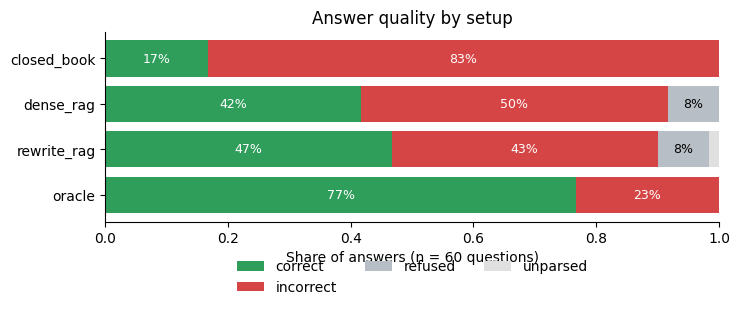

saved answer_results.csv and answer_quality.png to Drive


In [11]:
import matplotlib.pyplot as plt

if done:
    res.to_csv(f'{ROOT}/answer_results.csv', index=False)
    order = [s for s in SETUPS if s in tab.index]
    colors = {'correct': '#2F9E5B', 'incorrect': '#D64545', 'refused': '#B8BEC6', 'unparsed': '#E0E0E0'}
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    left = np.zeros(len(order))
    for v in ['correct', 'incorrect', 'refused', 'unparsed']:
        if v in tab:
            vals = tab.loc[order, v].values
            ax.barh(order, vals, left=left, color=colors[v], label=v)
            for y, (l0, w) in enumerate(zip(left, vals)):
                if w > 0.06:
                    ax.text(l0 + w / 2, y, f'{w:.0%}', ha='center', va='center', fontsize=9, color='white' if v != 'refused' else 'black')
            left += vals
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel(f'Share of answers (n = {len(sample)} questions)')
    ax.set_title('Answer quality by setup')
    ax.legend(ncol=3, frameon=False, loc='lower center', bbox_to_anchor=(0.5, -0.45))
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.savefig(f'{ROOT}/answer_quality.png', dpi=200, bbox_inches='tight')
    plt.show()
    print('saved answer_results.csv and answer_quality.png to Drive')

## What to send back
The results table, the by-type table, the McNemar line (section 4), and the 5 spot-checks (section 5).